### __Anna Kaczyńska, Kamila Mosińska__
# PROJECT 3: STIRRED (NOT SHAKEN)
-----

### ABSTRACT

### INTRODUCTION
--------

## EXERCISE 1:
### ODE SOLVER
### PART 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [116]:
class ode_solver:

    def __init__(self, func, params, h, y0, t0, tf, method='euler'):
        self.f = func
        self.params = params
        self.h = h
        self.y0 = y0
        self.t0 = t0
        self.tf = tf
        self.method = method
        self.Y = []
        self.T = []

    def euler(self, t, y, h):
        return self.h * self.f(t, y, self.params)

    def rk2(self, t, y, h):
        k1 = self.h * self.f(t, y, self.params)
        k2 = self.h * self.f(t + h/2, y + 1/2*k1, self.params)
        return k2

    def rk4(self, t, y, h):
        k1 = self.h * self.f(t, y, self.params)
        k2 = self.h * self.f(t + h/2, y + 1/2*k1, self.params)
        k3 = self.h * self.f(t + h/2, y + 1/2*k2, self.params)
        k4 =self.h * self.f(t + h, y + k3, self.params)
        return 1/6 * (k1 + 2*k2 + 2*k3 + k4)
    
    def solver(self):
        self.Y = []
        self.T = []
        self.Y.append(self.y0.copy())
        self.T.append(self.t0)
        h = self.h
        t0 = self.t0
        tf = self.tf
        method = self.method
        y_old = self.y0

        for t in np.arange(t0, tf, h):
            if method == 'euler':
                y_new = y_old + self.euler(t,y_old,h)
            elif method == 'rk2':
                y_new = y_old + self.rk2(t,y_old,h)
            elif method == 'rk4':
                y_new = y_old + self.rk4(t,y_old,h)

            y_old = y_new
            self.Y.append(y_old)
            self.T.append(t + h)

        Y = np.array(self.Y)
        T = np.array(self.T)

        return Y, T

### PART 2

In [117]:
def C_concentration(t, C, params):

    n, tau, C_in = params

    dCdt = np.zeros(n)
    dCdt[0] = (n/tau) * (C_in - C[0])

    for i in range(1, n):
        dCdt[i] = (n/tau) * (C[i-1] - C[i])

    return dCdt

results = {}
for n in [1, 2, 3]:
    params = (n, 2, 0)

    C0 = np.zeros(n)
    C0[0] = 1
    y0 = C0

    solve = ode_solver(C_concentration, params, 0.1, C0, 0, 10, method = 'rk4')
    Y, T = solve.solver()

    results[n] = (Y,T)


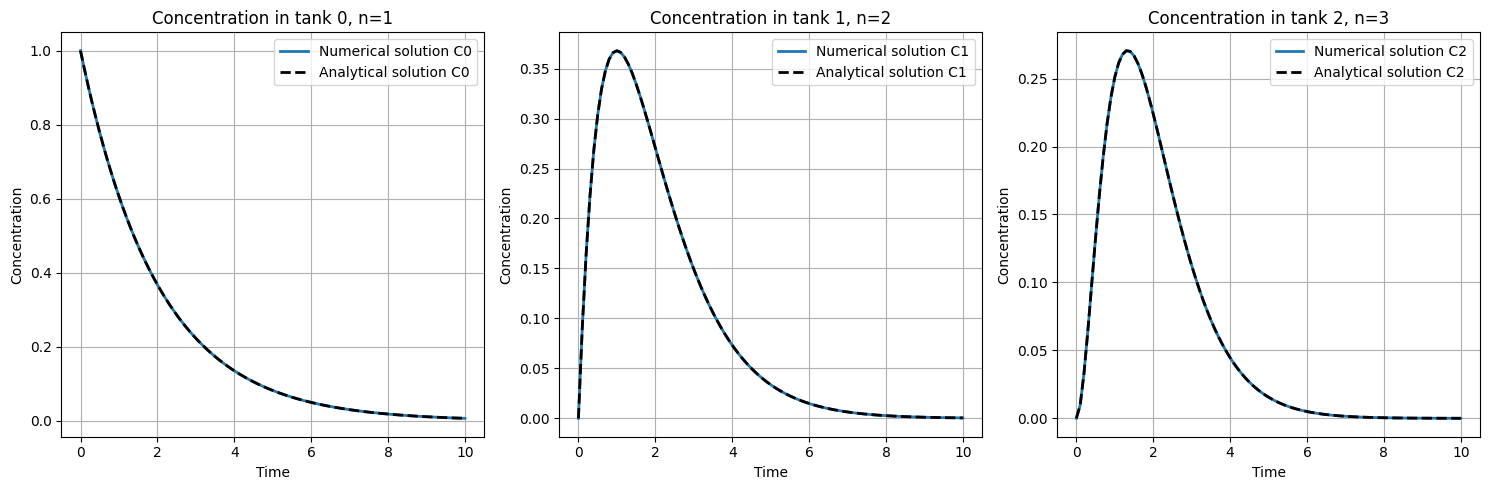

In [ ]:
tau = 2

Y_values = [results[n][0] for n in [1, 2, 3]]
T_values = [results[n][1] for n in [1, 2, 3]]

C_exact = [
    np.exp(-T_values[0]/tau),
    (2*T_values[1]/tau) * np.exp(-2*T_values[1]/tau),
    (9*T_values[2]**2/(2*tau**2)) * np.exp(-3*T_values[2]/tau)
]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i in range(3):
    ax[i].plot(T_values[i], Y_values[i][:,i], # change Y_values[i][:,i] to Y_values[i] if you want to display all the solutions
               label=f'Numerical solution C{i}', linewidth=2)

    ax[i].plot(T_values[i], C_exact[i], '--',
               label=f'Analytical solution C{i}',
               color='black', linewidth=2)

    ax[i].set_xlabel("Time")
    ax[i].set_ylabel("Concentration")
    ax[i].set_title(f"Concentration in tank {i}, n={i+1}")
    ax[i].legend()
    ax[i].grid()

plt.tight_layout()
plt.show()

### PART 3

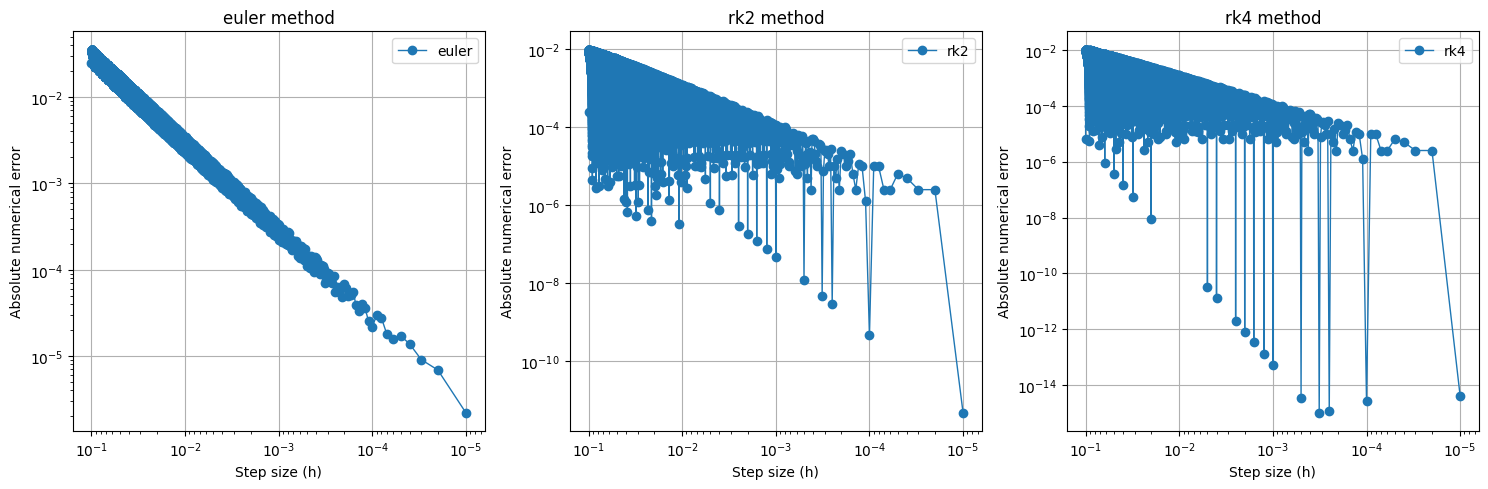

In [133]:
# for n = 3

h = np.linspace(0.1, 0.00001, 10000)
t_exact = 1
C_exact_3 = (9*t_exact**2/(2*tau**2)) * np.exp(-3*t_exact/tau)

methods = ['euler', 'rk2', 'rk4']
errors = {}

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, method in enumerate(methods):
    errors[method] = []

    for step in h:
        solve = ode_solver(
            C_concentration, (3, 2, 0), step,
            C0, 0, 1, method=method
        )

        Y, T = solve.solver()
        error = abs(C_exact_3 - Y[-1, 2])
        errors[method].append(error)

    ax[i].loglog(h, errors[method], 'o-', label=method, linewidth = 1)
    ax[i].invert_xaxis() # to order the x axis decreasingly
    ax[i].set_xlabel('Step size (h)')
    ax[i].set_ylabel('Absolute numerical error')
    ax[i].set_title(f'{method} method')
    ax[i].legend()
    ax[i].grid()

plt.tight_layout()
plt.show()

## TO DO: 

Does the numerical error scale as expected for Euler, RK2, and RK4?

-----
## EXERCISE 2:
### FITTING CSTR MODEL TO CFD MODEL
### PART 1

In [13]:
healthy_rect_1s = pd.read_csv('project3/data/Healthy_rect_1s.csv')
healthy_rect_1s

FileNotFoundError: [Errno 2] No such file or directory: 'project3/data/Healthy_rect_1s.csv'

In [14]:
import os

print(os.getcwd())

C:\Users\kompu\AppData\Local\Programs\Microsoft VS Code


------
### SUMMARY